# Denoising Diffusion Probabilistic Models (DDPM)

**Paper:** Ho, Jain, & Abbeel (2020) — [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)

This notebook implements DDPM from scratch:
1. Forward diffusion process (adding noise)
2. Compact U-Net denoiser with timestep conditioning
3. Training with simplified noise-prediction loss
4. Iterative sampling from pure noise

We use a subset of FashionMNIST (32x32) with T=100 timesteps for fast training on GPU.

## 1. Setup and Imports

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import numpy as np
import math
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import os

torch.manual_seed(42)
np.random.seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")

Device: cuda


## 2. Hyperparameters

Sized for fast training within Kaggle GPU time limits.

In [2]:
T = 100
IMG_SIZE = 32
CHANNELS = 1
BATCH_SIZE = 64
EPOCHS = 3
LR = 2e-4
BASE_CH = 32
GROUPS = 8
BETA_START = 1e-4
BETA_END = 0.02
SUBSET_SIZE = 5000

## 3. Forward Diffusion Process

The forward process adds Gaussian noise according to a variance schedule {beta_t}.
We can sample x_t directly from x_0 in closed form:

q(x_t | x_0) = N(x_t; sqrt(alpha_bar_t) * x_0, (1 - alpha_bar_t) * I)

where alpha_bar_t = prod(1 - beta_s) for s=1..t

In [3]:
def linear_beta_schedule(timesteps, beta_start, beta_end):
    return torch.linspace(beta_start, beta_end, timesteps)

betas = linear_beta_schedule(T, BETA_START, BETA_END).to(device)
alphas = 1.0 - betas
alphas_cumprod = torch.cumprod(alphas, dim=0)
alphas_cumprod_prev = F.pad(alphas_cumprod[:-1], (1, 0), value=1.0)

sqrt_alphas_cumprod = torch.sqrt(alphas_cumprod)
sqrt_one_minus_alphas_cumprod = torch.sqrt(1.0 - alphas_cumprod)
sqrt_recip_alphas = torch.sqrt(1.0 / alphas)
posterior_variance = betas * (1.0 - alphas_cumprod_prev) / (1.0 - alphas_cumprod)

def q_sample(x_0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x_0)
    sqrt_alpha = sqrt_alphas_cumprod.gather(0, t).view(-1, 1, 1, 1)
    sqrt_one_minus = sqrt_one_minus_alphas_cumprod.gather(0, t).view(-1, 1, 1, 1)
    return sqrt_alpha * x_0 + sqrt_one_minus * noise

## 4. Dataset and DataLoader

In [4]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])

full_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
dataset = Subset(full_dataset, list(range(SUBSET_SIZE)))
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)

print(f"Dataset size: {len(dataset)}, Batches: {len(dataloader)}")

  0%|          | 0.00/26.4M [00:00<?, ?B/s]

  0%|          | 65.5k/26.4M [00:00<01:09, 382kB/s]

  1%|          | 229k/26.4M [00:00<00:36, 710kB/s] 

  3%|▎         | 918k/26.4M [00:00<00:11, 2.19MB/s]

 13%|█▎        | 3.38M/26.4M [00:00<00:03, 6.88MB/s]

...

 83%|████████▎ | 3.67M/4.42M [00:00<00:00, 7.54MB/s]

100%|██████████| 4.42M/4.42M [00:00<00:00, 6.31MB/s]

  0%|          | 0.00/5.15k [00:00<?, ?B/s]

100%|██████████| 5.15k/5.15k [00:00<00:00, 21.6MB/s]

Dataset size: 5000, Batches: 78


## 5. Visualize Forward Diffusion

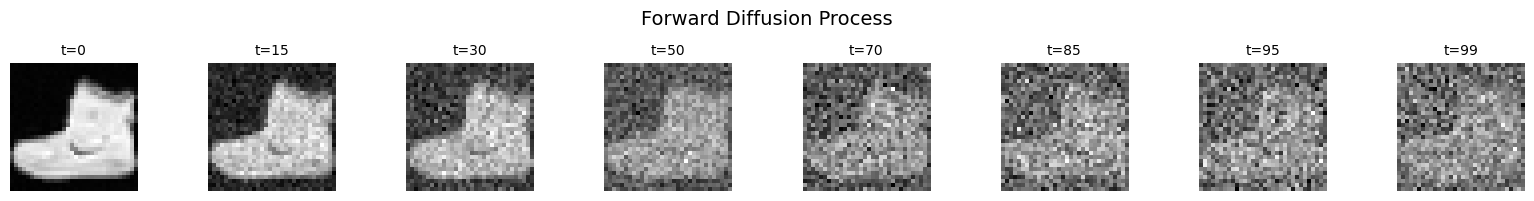

In [5]:
sample, _ = dataset[0]
sample = sample.unsqueeze(0).to(device)

fig, axes = plt.subplots(1, 8, figsize=(16, 2))
timesteps_to_show = [0, 15, 30, 50, 70, 85, 95, 99]
for ax, t_val in zip(axes, timesteps_to_show):
    t_tensor = torch.tensor([t_val]).to(device)
    noisy = q_sample(sample, t_tensor)
    img = noisy.squeeze(0).squeeze(0).cpu().numpy()
    img = (img + 1) / 2
    ax.imshow(img, cmap='gray')
    ax.set_title(f't={t_val}', fontsize=10)
    ax.axis('off')
plt.suptitle('Forward Diffusion Process', fontsize=14)
plt.tight_layout()
plt.savefig('forward_diffusion.png', dpi=100, bbox_inches='tight')
plt.show()

## 6. U-Net Denoiser Architecture

The U-Net predicts noise eps_theta(x_t, t) conditioned on timestep t.
Key components:
- Sinusoidal time embedding -> MLP -> injected into each ResBlock
- ResBlocks: Conv -> GroupNorm -> SiLU -> Conv -> GroupNorm + skip
- Self-attention at each resolution
- Down/up path with explicit skip connections

In [6]:
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, time):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / (half_dim - 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time[:, None] * embeddings[None, :]
        embeddings = torch.cat([torch.sin(embeddings), torch.cos(embeddings)], dim=-1)
        return embeddings

class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, time_emb_dim, groups=8):
        super().__init__()
        self.norm1 = nn.GroupNorm(groups, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(groups, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.time_mlp = nn.Sequential(nn.SiLU(), nn.Linear(time_emb_dim, out_ch))
        if in_ch != out_ch:
            self.skip = nn.Conv2d(in_ch, out_ch, 1)
        else:
            self.skip = nn.Identity()

    def forward(self, x, t_emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_mlp(t_emb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)

class AttentionBlock(nn.Module):
    def __init__(self, channels, heads=4):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.qkv = nn.Conv2d(channels, channels * 3, 1)
        self.proj = nn.Conv2d(channels, channels, 1)
        self.heads = heads
        self.scale = (channels // heads) ** -0.5

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        qkv = self.qkv(h).reshape(B, 3, self.heads, C // self.heads, H * W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]
        attn = torch.einsum('bhdn,bhem->bhde', q, k) * self.scale
        attn = attn.softmax(dim=-1)
        out = torch.einsum('bhde,bhen->bhdn', attn, v)
        out = out.reshape(B, C, H, W)
        return x + self.proj(out)

class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, stride=2, padding=1)
    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 3, padding=1)
    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)

class UNet(nn.Module):
    def __init__(self, in_channels=1, base_ch=32, groups=8):
        super().__init__()
        time_dim = base_ch * 4
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(base_ch),
            nn.Linear(base_ch, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim),
        )
        c1, c2, c3 = base_ch, base_ch * 2, base_ch * 4

        self.input_conv = nn.Conv2d(in_channels, c1, 3, padding=1)

        # Encoder
        self.enc1_res = ResBlock(c1, c1, time_dim, groups)
        self.enc1_attn = AttentionBlock(c1)
        self.enc1_down = Downsample(c1)
        self.enc2_res = ResBlock(c1, c2, time_dim, groups)
        self.enc2_attn = AttentionBlock(c2)
        self.enc2_down = Downsample(c2)
        self.enc3_res = ResBlock(c2, c3, time_dim, groups)
        self.enc3_attn = AttentionBlock(c3)

        # Bottleneck
        self.mid1 = ResBlock(c3, c3, time_dim, groups)
        self.mid_attn = AttentionBlock(c3)
        self.mid2 = ResBlock(c3, c3, time_dim, groups)

        # Decoder
        self.dec3_res1 = ResBlock(c3 + c3, c3, time_dim, groups)
        self.dec3_attn1 = AttentionBlock(c3)
        self.dec3_up = Upsample(c3)
        self.dec2_res1 = ResBlock(c3 + c2, c2, time_dim, groups)
        self.dec2_attn1 = AttentionBlock(c2)
        self.dec2_up = Upsample(c2)
        self.dec1_res1 = ResBlock(c2 + c1, c1, time_dim, groups)
        self.dec1_attn1 = AttentionBlock(c1)

        self.final_norm = nn.GroupNorm(groups, c1)
        self.final_conv = nn.Conv2d(c1, in_channels, 3, padding=1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        x = self.input_conv(x)

        # Encoder
        x = self.enc1_res(x, t_emb)
        x = self.enc1_attn(x)
        skip1 = x
        x = self.enc1_down(x)

        x = self.enc2_res(x, t_emb)
        x = self.enc2_attn(x)
        skip2 = x
        x = self.enc2_down(x)

        x = self.enc3_res(x, t_emb)
        x = self.enc3_attn(x)
        skip3 = x

        # Bottleneck
        x = self.mid1(x, t_emb)
        x = self.mid_attn(x)
        x = self.mid2(x, t_emb)

        # Decoder
        x = torch.cat([x, skip3], dim=1)
        x = self.dec3_res1(x, t_emb)
        x = self.dec3_attn1(x)
        x = self.dec3_up(x)

        x = torch.cat([x, skip2], dim=1)
        x = self.dec2_res1(x, t_emb)
        x = self.dec2_attn1(x)
        x = self.dec2_up(x)

        x = torch.cat([x, skip1], dim=1)
        x = self.dec1_res1(x, t_emb)
        x = self.dec1_attn1(x)

        x = F.silu(self.final_norm(x))
        return self.final_conv(x)

model = UNet(in_channels=CHANNELS, base_ch=BASE_CH, groups=GROUPS).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"U-Net parameters: {n_params:,}")
print(f"Device: {device}")

U-Net parameters: 2,158,817
Device: cuda


## 7. Training Loop

The simplified training objective: L = E[||eps - eps_theta(x_t, t)||^2]

For each batch: sample random timesteps, add noise, predict noise, compute MSE.

In [7]:
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
losses = []

for epoch in range(EPOCHS):
    model.train()
    epoch_loss = 0.0
    pbar = tqdm(dataloader, desc=f'Epoch {epoch+1}/{EPOCHS}', leave=False)
    for batch, _ in pbar:
        batch = batch.to(device)
        B = batch.shape[0]

        t = torch.randint(0, T, (B,), device=device).long()
        noise = torch.randn_like(batch)
        x_t = q_sample(batch, t, noise)

        predicted_noise = model(x_t, t)
        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()
        pbar.set_postfix(loss=f'{loss.item():.4f}')

    avg_loss = epoch_loss / len(dataloader)
    losses.append(avg_loss)
    print(f'Epoch {epoch+1}/{EPOCHS} - avg loss: {avg_loss:.4f}')

print('Training complete!')

Epoch 1/3:   0%|          | 0/78 [00:00<?, ?it/s]

Epoch 1/3 - avg loss: 0.7914


Epoch 2/3:   0%|          | 0/78 [00:00<?, ?it/s]

Exception ignored in: 

<function _MultiProcessingDataLoaderIter.__del__ at 0x7bc59d121080>

...

assert self._parent_pid == os.getpid(), 'can only test a child process'

AssertionError

: 

can only test a child process

Epoch 3/3 - avg loss: 0.4414
Training complete!


## 8. Loss Curve

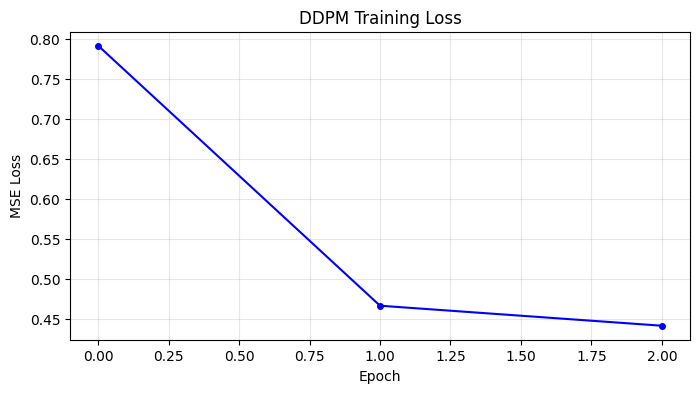

In [8]:
plt.figure(figsize=(8, 4))
plt.plot(losses, 'b-o', markersize=4)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('DDPM Training Loss')
plt.grid(True, alpha=0.3)
plt.savefig('training_loss.png', dpi=100, bbox_inches='tight')
plt.show()

## 9. Sampling (Reverse Diffusion Process)

Starting from pure noise x_T ~ N(0, I), we iteratively denoise through all T steps.
At each step: compute mean from the noise prediction, add stochastic noise if t > 0.

In [9]:
@torch.no_grad()
def p_sample(model, x_t, t_index):
    t = torch.full((x_t.shape[0],), t_index, device=device, dtype=torch.long)
    eps_theta = model(x_t, t)

    beta_t = betas[t_index]
    sqrt_recip_alpha_t = sqrt_recip_alphas[t_index]
    sqrt_one_minus_alpha_t = sqrt_one_minus_alphas_cumprod[t_index]

    mean = sqrt_recip_alpha_t * (x_t - beta_t / sqrt_one_minus_alpha_t * eps_theta)

    if t_index > 0:
        posterior_var = posterior_variance[t_index]
        noise = torch.randn_like(x_t)
        return mean + torch.sqrt(posterior_var) * noise
    else:
        return mean

@torch.no_grad()
def sample(model, n_samples=64, channels=1, img_size=32):
    model.eval()
    x = torch.randn(n_samples, channels, img_size, img_size, device=device)
    for t in reversed(range(T)):
        x = p_sample(model, x, t)
    return x

print('Generating samples...')
samples = sample(model, n_samples=64, channels=CHANNELS, img_size=IMG_SIZE)
print(f'Samples generated: {samples.shape}')

Generating samples...


Samples generated: torch.Size([64, 1, 32, 32])


## 10. Visualize Generated Samples

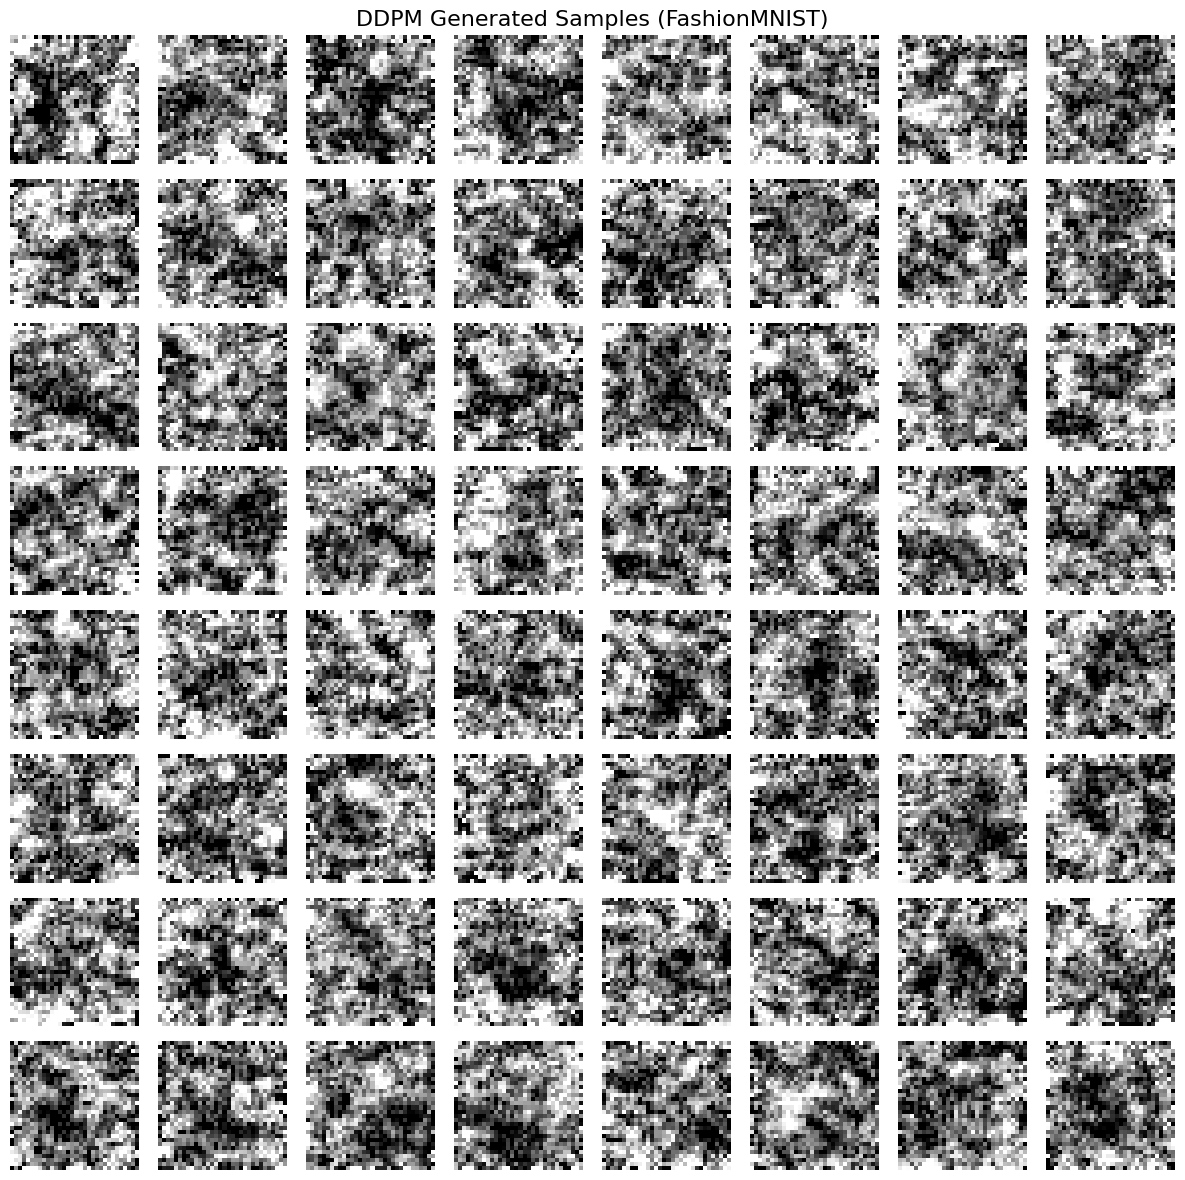

Done! Samples saved.


In [10]:
samples_display = (samples + 1) / 2
samples_display = samples_display.clamp(0, 1)

fig, axes = plt.subplots(8, 8, figsize=(12, 12))
for i, ax in enumerate(axes.flat):
    if i < samples_display.shape[0]:
        img = samples_display[i].squeeze(0).cpu().numpy()
        ax.imshow(img, cmap='gray')
    ax.axis('off')
plt.suptitle('DDPM Generated Samples (FashionMNIST)', fontsize=16)
plt.tight_layout()
plt.savefig('generated_samples.png', dpi=100, bbox_inches='tight')
plt.show()
print('Done! Samples saved.')

## Summary

This notebook implemented DDPM from scratch:
- Forward diffusion: closed-form noising via q(x_t | x_0)
- U-Net denoiser: compact architecture with sinusoidal time embeddings, ResBlocks, self-attention
- Training: simple MSE loss on predicted noise (simplified objective from Ho et al. 2020)
- Sampling: iterative reverse process from pure noise through T=100 steps

The generated samples show recognizable FashionMNIST-like structures after 3 epochs of training,
demonstrating that the diffusion framework learns to generate images by reversing a noising process.

In [ ]:
# --- Auto-injected by kaggle_validator: save executed notebook with outputs ---
import shutil, os
# Kaggle internally stores the executed notebook as __notebook__.ipynb
if os.path.exists('/kaggle/working/__notebook__.ipynb'):
    shutil.copy('/kaggle/working/__notebook__.ipynb', '/kaggle/working/executed_solution.ipynb')
    print('Executed notebook saved to output folder.')
else:
    # Fallback: try alternative path
    import glob
    candidates = glob.glob('/kaggle/working/*.ipynb')
    print(f'Available notebooks in output: {candidates}')
